In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [1]:
import os
import shutil
import random

# Paths
DATASET_PATHS = [
    "/kaggle/input/datasets/tahirlee/histopoc-histopathology-dataset/Train/Train",
    "/kaggle/input/datasets/tahirlee/histopoc-histopathology-dataset/Test/Test"  
]
OUTPUT_PATH = "/kaggle/working/train1"

# Classes in dataset
classes = ["Chorionic_villi","Decidual_tissue" , "Hemorrhage", "Trophoblastic_tissue" ]
os.makedirs(OUTPUT_PATH, exist_ok=True)

for cls in classes:
    dst_folder = os.path.join(OUTPUT_PATH, cls.replace(" ", "_"))
    os.makedirs(dst_folder, exist_ok=True)

    total_count = 0

    # Loop through all dataset splits
    for dataset_path in DATASET_PATHS:
        src_folder = os.path.join(dataset_path, cls)

        if not os.path.exists(src_folder):
            continue

        images = [
            f for f in os.listdir(src_folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        for img in images:
            src_path = os.path.join(src_folder, img)

            # Avoid overwriting same filename
            new_name = f"{os.path.basename(dataset_path)}_{img}"
            dst_path = os.path.join(dst_folder, new_name)

            shutil.copy2(src_path, dst_path)

        total_count += len(images)

    print(f"Class {cls}: {total_count} images copied.")

print("All train + test + validation images merged into one train folder.")

Class Chorionic_villi: 1781 images copied.
Class Decidual_tissue: 1275 images copied.
Class Hemorrhage: 1559 images copied.
Class Trophoblastic_tissue: 1051 images copied.
All train + test + validation images merged into one train folder.


In [2]:
train_dir = "/kaggle/working/train1"

# **Data Visualization**

Classes: ['Decidual_tissue', 'Chorionic_villi', 'Trophoblastic_tissue', 'Hemorrhage']


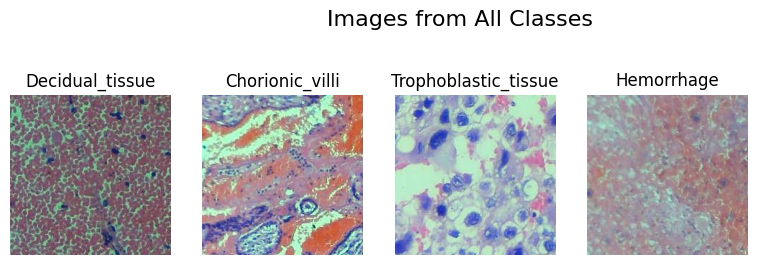

In [3]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os
import random

classes = os.listdir(train_dir)
print("Classes:", classes)

# Show one random image from each class
plt.figure(figsize=(12, 6))
for i, cls in enumerate(classes):
    cls_path = os.path.join(train_dir, cls)

    # Pick a random image from that class
    img_name = random.choice(os.listdir(cls_path))
    img_path = os.path.join(cls_path, img_name)

    # Read image
    img = mpimg.imread(img_path)

    # Plot
    plt.subplot(2, 5, i+1)  # 2 rows, 5 columns
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.suptitle("Images from All Classes", fontsize=16)
plt.show()

/tmp/ipykernel_58/1595876158.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="label", y="count", data=df, palette=he_colors)
/tmp/ipykernel_58/1595876158.py:15: UserWarning: The palette list has more values (5) than needed (4), which may not be intended.
  sns.barplot(x="label", y="count", data=df, palette=he_colors)


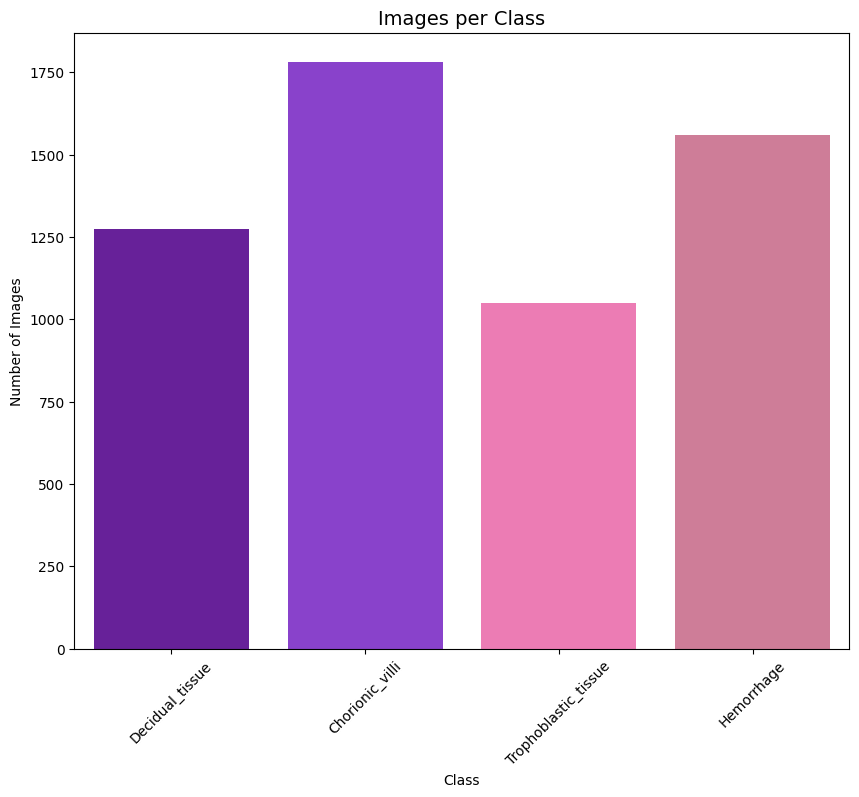

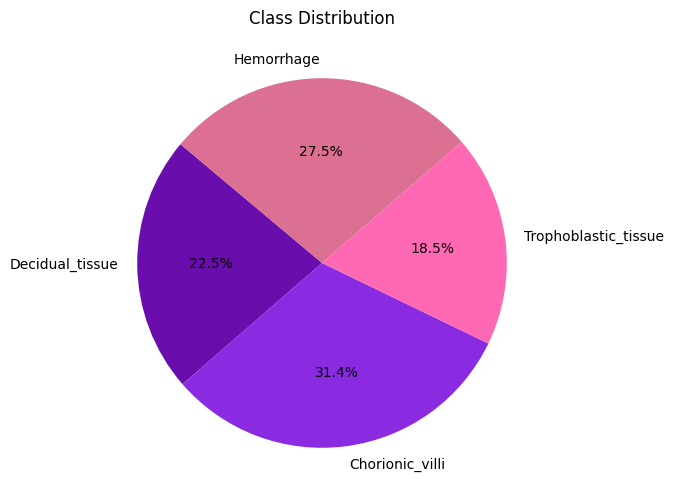

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Count images per class
df = pd.DataFrame([(cls, len(os.listdir(os.path.join(train_dir, cls))))
                   for cls in os.listdir(train_dir)], columns=["label", "count"])

# H&E-inspired colors (purple/blue + pink)
he_colors = ["#6A0DAD", "#8A2BE2", "#FF69B4", "#DB7093", "#BA55D3"]

# Bar chart
plt.figure(figsize=(10, 8))
sns.barplot(x="label", y="count", data=df, palette=he_colors)
plt.xticks(rotation=45)
plt.title("Images per Class", fontsize=14)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

# Pie chart
df.set_index("label")["count"].plot(kind="pie", autopct="%1.1f%%",
                                    startangle=140, figsize=(6,6),
                                    colors=he_colors)
plt.title("Class Distribution")
plt.ylabel("")
plt.show()

# **Split Train/Test Before Augmentation**

In [5]:
import os
import shutil
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image
import numpy as np
import random

DATASET_PATH = "/kaggle/working/train1"
OUTPUT_TRAIN = "/kaggle/working/train_aug"
OUTPUT_TEST = "/kaggle/working/test"

classes = os.listdir(DATASET_PATH)
os.makedirs(OUTPUT_TRAIN, exist_ok=True)
os.makedirs(OUTPUT_TEST, exist_ok=True)

# Copy 100 images per class to test folder, rest to train folder
for cls in classes:
    cls_src = os.path.join(DATASET_PATH, cls)
    images = [f for f in os.listdir(cls_src) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    random.shuffle(images)

    test_images = images[:100]
    train_images = images[100:]

    # Create class folders
    os.makedirs(os.path.join(OUTPUT_TEST, cls), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_TRAIN, cls), exist_ok=True)

    # Copy images
    for img in test_images:
        shutil.copy2(os.path.join(cls_src, img), os.path.join(OUTPUT_TEST, cls, img))
    for img in train_images:
        shutil.copy2(os.path.join(cls_src, img), os.path.join(OUTPUT_TRAIN, cls, img))

    print(f"{cls}: {len(train_images)} train images, {len(test_images)} test images")

2026-08-09 18:12:20.436936: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1786299140.648931      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1786299140.708945      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1786299141.212718      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1786299141.212777      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1786299141.212784      58 computation_placer.cc:177] computation placer alr

Decidual_tissue: 1175 train images, 100 test images
Chorionic_villi: 1681 train images, 100 test images
Trophoblastic_tissue: 951 train images, 100 test images
Hemorrhage: 1459 train images, 100 test images


# **Oversampling**

In [7]:
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.05,
    height_shift_range=0.05,
    shear_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

target_count = 1400  # target per class

for cls in os.listdir(OUTPUT_TRAIN):
    cls_path = os.path.join(OUTPUT_TRAIN, cls)
    images = [f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    current_count = len(images)

    if current_count >= target_count:
        print(f"Skipping {cls}: {current_count} images already present.")
        continue

    needed = target_count - current_count
    print(f"Augmenting {cls}: generating {needed} images...")

    img_index = 0
    for _ in range(needed):
        img_path = os.path.join(cls_path, images[img_index % len(images)])
        img = np.expand_dims(np.array(Image.open(img_path).convert("RGB")), axis=0)
        aug_iter = datagen.flow(img, batch_size=1, save_to_dir=cls_path, save_prefix="aug", save_format="jpg")
        next(aug_iter)
        img_index += 1

    # ✅ Print final image count for this class
    final_count = len([f for f in os.listdir(cls_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    print(f"✅ {cls} final image count: {final_count}")

print("✅ Train set augmented to target images per class.")

Augmenting Decidual_tissue: generating 3 images...
✅ Decidual_tissue final image count: 1400
Skipping Chorionic_villi: 1681 images already present.
Augmenting Trophoblastic_tissue: generating 8 images...
✅ Trophoblastic_tissue final image count: 1400
Skipping Hemorrhage: 1459 images already present.
✅ Train set augmented to target images per class.


# **Imports**

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNet
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_curve
from tqdm import tqdm
import os
import random

# **Hyperparameters**

In [9]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
TEMPERATURE = 0.5
PROJECTION_DIM = 128
CHECKPOINT_DIR = "./checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# **Data Augmentation & Loading**

In [10]:
def random_augment(image):
    image = tf.image.resize(image, [256, 256])
    image = tf.image.random_crop(image, size=[224, 224, 3])
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, 0.1)
    image = tf.image.random_contrast(image, 0.8, 1.2)
    image = tf.clip_by_value(image, 0, 1)
    return image

def load_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = img / 255.0
    return img

def ssl_generator(image_paths, batch_size):
    while True:
        batch_paths = random.sample(image_paths, batch_size)
        x1_batch = np.array([random_augment(load_image(p)).numpy() for p in batch_paths])
        x2_batch = np.array([random_augment(load_image(p)).numpy() for p in batch_paths])
        yield x1_batch, x2_batch

# **SimCLR Model with MobileNet**

In [11]:
def create_simclr_model(projection_dim=128):
    base_model = MobileNet(
        include_top=False, 
        weights='imagenet', 
        input_shape=(224,224,3)
    )

    # Freeze all layers except last 30
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    for layer in base_model.layers[-30:]:
        layer.trainable = True

    inputs = layers.Input(shape=(224,224,3))
    x = base_model(inputs, training=True)
    x = layers.GlobalAveragePooling2D(name="gap")(x)

    # Projection head
    x = layers.Dense(512)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    
    x = layers.Dense(512)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    
    outputs = layers.Dense(projection_dim)(x)

    model = models.Model(inputs, outputs)
    return model

simclr_model = create_simclr_model(PROJECTION_DIM)

I0000 00:00:1786299239.558138      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786299239.564125      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


# **NT-Xent Loss**

In [12]:
def nt_xent_loss(z_i, z_j, temperature=0.5):
    batch_size = tf.shape(z_i)[0]
    N = 2 * batch_size

    z_i = tf.math.l2_normalize(z_i, axis=1)
    z_j = tf.math.l2_normalize(z_j, axis=1)

    representations = tf.concat([z_i, z_j], axis=0)
    sim_matrix = tf.matmul(representations, representations, transpose_b=True) / temperature

    mask = tf.eye(N, dtype=tf.bool)
    large_negative = tf.fill([N, N], -1e9)
    sim_matrix = tf.where(mask, large_negative, sim_matrix)

    labels = tf.concat([tf.range(batch_size, N), tf.range(0, batch_size)], axis=0)
    loss = tf.keras.losses.sparse_categorical_crossentropy(labels, sim_matrix, from_logits=True)
    return tf.reduce_mean(loss)

# **Prepare Dataset**

In [13]:
train_dir = OUTPUT_TRAIN
test_dir = OUTPUT_TEST

# Prepare image paths
def get_image_paths_labels(folder):
    image_paths, labels = [], []
    classes = os.listdir(folder)
    for cls in classes:
        cls_dir = os.path.join(folder, cls)
        for f in os.listdir(cls_dir):
            if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                image_paths.append(os.path.join(cls_dir, f))
                labels.append(cls)
    return image_paths, labels

train_paths, train_labels = get_image_paths_labels(train_dir)
test_paths, test_labels = get_image_paths_labels(test_dir)

print(f"Train: {len(train_paths)}, Test: {len(test_paths)}")

steps_per_epoch = max(1, len(train_paths)//BATCH_SIZE)

Train: 5940, Test: 400


# **SSL Training Loop**

In [14]:
train_losses = []

optimizer = tf.keras.optimizers.Adam(3e-4)
best_loss = np.inf

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    epoch_loss = 0
    gen = ssl_generator(train_paths, BATCH_SIZE)
    loop = tqdm(range(steps_per_epoch), desc="Training", ncols=100)

    for step in loop:
        x1, x2 = next(gen)
        with tf.GradientTape() as tape:
            z1 = simclr_model(x1, training=True)
            z2 = simclr_model(x2, training=True)
            loss = nt_xent_loss(z1, z2, TEMPERATURE)

        grads = tape.gradient(loss, simclr_model.trainable_variables)
        optimizer.apply_gradients(zip(grads, simclr_model.trainable_variables))
        epoch_loss += loss.numpy()
        loop.set_postfix(loss=f"{loss.numpy():.4f}")

    epoch_loss /= steps_per_epoch
    train_losses.append(epoch_loss)

    print(f"Epoch {epoch+1}: loss={epoch_loss:.4f}")

    if epoch_loss < best_loss:
        best_loss = epoch_loss
        simclr_model.save(os.path.join(CHECKPOINT_DIR, "best_simclr_model.keras"))
        print("Model improved — saved ✔")


Epoch 1/10


Training: 100%|██████████████████████████████████████| 185/185 [03:16<00:00,  1.06s/it, loss=2.3539]


Epoch 1: loss=2.4205
Model improved — saved ✔

Epoch 2/10


Training: 100%|██████████████████████████████████████| 185/185 [03:12<00:00,  1.04s/it, loss=2.2832]


Epoch 2: loss=2.2991
Model improved — saved ✔

Epoch 3/10


...

Epoch 8: loss=2.2502
Model improved — saved ✔

Epoch 9/10


Training: 100%|██████████████████████████████████████| 185/185 [03:12<00:00,  1.04s/it, loss=2.2501]


Epoch 9: loss=2.2472
Model improved — saved ✔

Epoch 10/10


Training: 100%|██████████████████████████████████████| 185/185 [03:11<00:00,  1.04s/it, loss=2.2427]


Epoch 10: loss=2.2460
Model improved — saved ✔


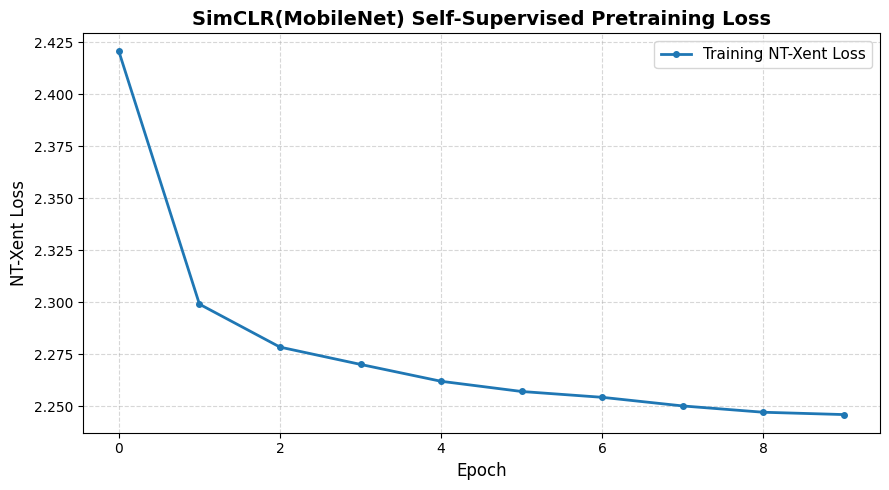

In [15]:
plt.figure(figsize=(9,5))

plt.plot(
    train_losses,
    linewidth=2,
    marker='o',
    markersize=4,
    label="Training NT-Xent Loss"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NT-Xent Loss", fontsize=12)

plt.title(
    "SimCLR(MobileNet) Self-Supervised Pretraining Loss",
    fontsize=14,
    fontweight="bold"
)

plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# **Linear Evaluation (Batched)**

In [16]:
# -----------------------------
# Encoder from SimCLR
# -----------------------------
encoder = tf.keras.Model(
    inputs=simclr_model.input,
    outputs=simclr_model.get_layer("gap").output
)

# -----------------------------
# Embedding Extraction
# -----------------------------
def extract_embeddings_batch(model, image_paths, batch_size=32):
    imgs = np.array([load_image(p).numpy() for p in image_paths])
    embeddings = model.predict(imgs, batch_size=batch_size, verbose=1)
    return embeddings

X_train = extract_embeddings_batch(encoder, train_paths, BATCH_SIZE)
X_val = extract_embeddings_batch(encoder, test_paths, BATCH_SIZE)

# -----------------------------
# Label Encoding
# -----------------------------
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
# Fit on all labels
le.fit(train_labels + test_labels)  # removed .tolist()

# -----------------------------
# Linear Classifier (Logistic Regression)
# -----------------------------
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

clf = LogisticRegression(max_iter=2000, solver='saga', multi_class='ovr')
clf.fit(X_train, train_labels)

preds = clf.predict(X_val)
probs = clf.predict_proba(X_val)

acc = accuracy_score(test_labels, preds)
print(f"Test Accuracy: {acc:.4f}")

print("\nClassification Report:")
print(classification_report(test_labels, preds, target_names=le.classes_))

I0000 00:00:1786301212.166787     146 service.cc:152] XLA service 0x7c53401da1c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1786301212.166826     146 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1786301212.166830     146 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
2026-08-09 18:46:59.840957: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-09 18:46:59.979055: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1786301220.865049     146 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for th

185/186 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step

2026-08-09 18:47:13.398964: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-09 18:47:13.536164: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


186/186 ━━━━━━━━━━━━━━━━━━━━ 24s 73ms/step
11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step

2026-08-09 18:47:23.826431: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-09 18:47:23.965204: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 693ms/step


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Test Accuracy: 0.8725

Classification Report:
                      precision    recall  f1-score   support

     Chorionic_villi       0.96      0.99      0.98       100
     Decidual_tissue       0.76      0.76      0.76       100
          Hemorrhage       0.80      0.82      0.81       100
Trophoblastic_tissue       0.98      0.92      0.95       100

            accuracy                           0.87       400
           macro avg       0.87      0.87      0.87       400
        weighted avg       0.87      0.87      0.87       400



# **Evaluation**

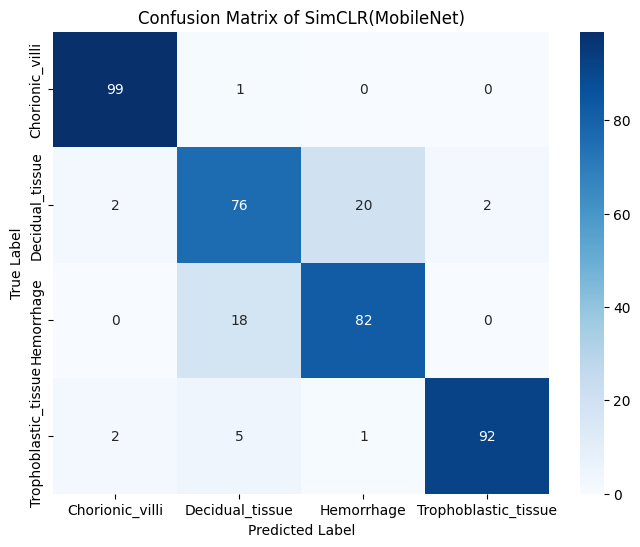

In [17]:
# ==========================
# Confusion Matrix
# ==========================
cm = confusion_matrix(test_labels, preds)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix of SimCLR(MobileNet)")
plt.show()

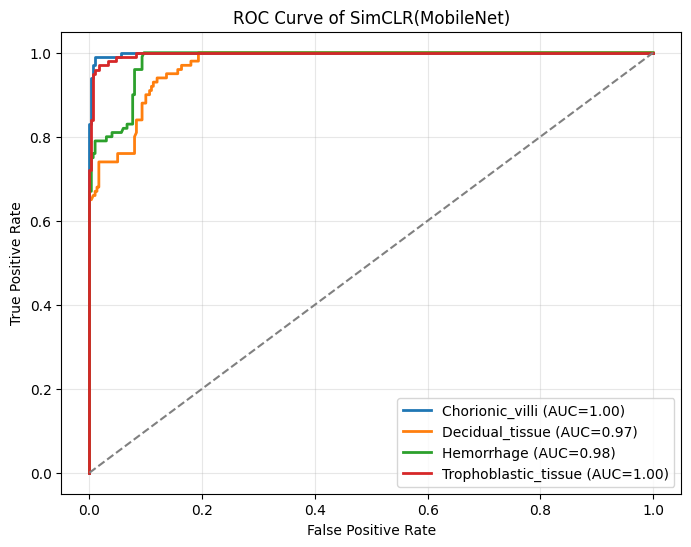

In [18]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np


# Number of classes
n_classes = len(le.classes_)


# Binarize labels
y_test_bin = label_binarize(
    test_labels,
    classes=le.classes_
)


# Fix binary classification shape
if n_classes == 2:
    y_test_bin = np.hstack(
        [
            1 - y_test_bin,
            y_test_bin
        ]
    )



plt.figure(figsize=(8,6))


for i in range(n_classes):

    if np.sum(y_test_bin[:,i]) == 0:
        print(
            f"Warning: {le.classes_[i]} missing in test set"
        )
        continue


    fpr, tpr, _ = roc_curve(
        y_test_bin[:,i],
        probs[:,i]
    )


    roc_auc = auc(
        fpr,
        tpr
    )


    plt.plot(
        fpr,
        tpr,
        lw=2,
        label=f"{le.classes_[i]} (AUC={roc_auc:.2f})"
    )



plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="gray"
)


plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve of SimCLR(MobileNet)"
)

plt.legend(
    loc="lower right"
)

plt.grid(alpha=0.3)

plt.show()

# **Bootstrap Confidence Interval for Accuracy**
statistical significance testing 


Bootstrap Accuracy CI:
Mean Accuracy: 0.8723
CI: [0.8400, 0.9026]


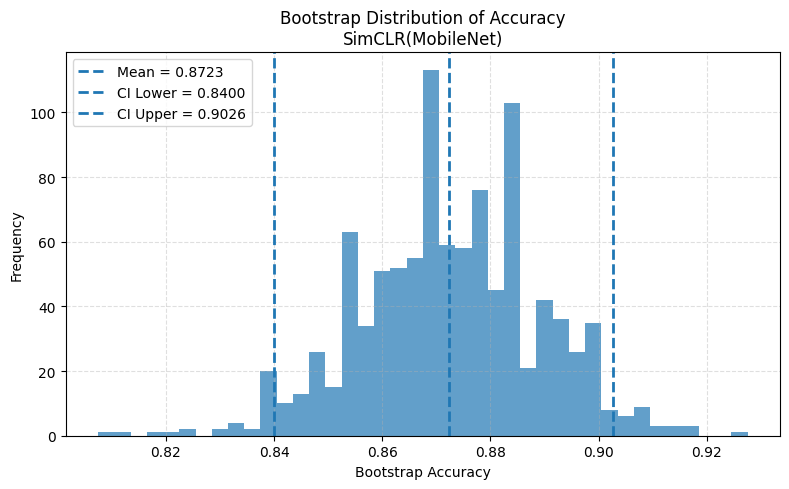

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score


# ============================================================
# BOOTSTRAP CONFIDENCE INTERVAL
# ============================================================

def bootstrap_ci(
    y_true,
    y_pred,
    n_iterations=1000,
    confidence=0.95
):

    scores = []

    n = len(y_true)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)


    for _ in range(n_iterations):

        indices = np.random.randint(
            0,
            n,
            n
        )


        score = accuracy_score(
            y_true[indices],
            y_pred[indices]
        )


        scores.append(score)



    scores = np.array(scores)


    lower = np.percentile(
        scores,
        (1-confidence)/2*100
    )


    upper = np.percentile(
        scores,
        (1+confidence)/2*100
    )


    return (
        scores,
        np.mean(scores),
        lower,
        upper
    )



# ============================================================
# RUN BOOTSTRAP
# ============================================================

bootstrap_scores, mean_acc, lower, upper = bootstrap_ci(
    test_labels,
    preds,
    n_iterations=1000
)



print("\nBootstrap Accuracy CI:")
print(f"Mean Accuracy: {mean_acc:.4f}")
print(f"CI: [{lower:.4f}, {upper:.4f}]")



# ============================================================
# BOOTSTRAP DISTRIBUTION PLOT
# ============================================================

plt.figure(figsize=(8,5))


plt.hist(
    bootstrap_scores,
    bins=40,
    alpha=0.7
)



# Mean
plt.axvline(
    mean_acc,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_acc:.4f}"
)



# Lower CI
plt.axvline(
    lower,
    linestyle="--",
    linewidth=2,
    label=f"CI Lower = {lower:.4f}"
)



# Upper CI
plt.axvline(
    upper,
    linestyle="--",
    linewidth=2,
    label=f"CI Upper = {upper:.4f}"
)



plt.xlabel(
    "Bootstrap Accuracy"
)

plt.ylabel(
    "Frequency"
)


plt.title(
    "Bootstrap Distribution of Accuracy\nSimCLR(MobileNet)"
)


plt.legend()


plt.grid(
    linestyle="--",
    alpha=0.4
)


plt.tight_layout()

plt.show()

# **TTA + Uncertainty**

In [20]:
import scipy.stats as stats

# --------------------------
# Plain embedding extraction
# --------------------------
def extract_embeddings_batch(model, image_paths, batch_size=32):
    all_embeddings = []

    for i in tqdm(range(0, len(image_paths), batch_size), desc="Extracting Train Embeddings"):
        batch = image_paths[i:i+batch_size]
        imgs = np.array([load_image(p).numpy() for p in batch])
        embs = model.predict(imgs, verbose=0)
        all_embeddings.append(embs)

    return np.concatenate(all_embeddings, axis=0)


# --------------------------
# TTA Augmentation
# --------------------------
def tta_augment(image):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, 0.2)
    image = tf.image.random_contrast(image, 0.8, 1.2)
    image = tf.clip_by_value(image, 0, 1)
    return image


# --------------------------
# TTA Embedding Extraction
# --------------------------
def extract_embeddings_tta(model, image_paths, tta_runs=5, batch_size=32):
    all_embeddings = []

    for i in tqdm(range(0, len(image_paths), batch_size), desc="TTA Embeddings"):
        batch_paths = image_paths[i:i+batch_size]

        tta_embeddings = []

        for _ in range(tta_runs):
            imgs = []

            for p in batch_paths:
                img = load_image(p)
                img = tta_augment(img)
                imgs.append(img.numpy())

            imgs = np.array(imgs)
            emb = model.predict(imgs, verbose=0)
            tta_embeddings.append(emb)

        tta_embeddings = np.array(tta_embeddings)

        # Mean embedding (final representation)
        mean_emb = np.mean(tta_embeddings, axis=0)

        all_embeddings.append(mean_emb)

    return np.concatenate(all_embeddings, axis=0)


# ==========================
# Extract embeddings
# ==========================
# ✅ Train embeddings (NO TTA)
X_train = extract_embeddings_batch(encoder, train_paths)

# ✅ Validation embeddings (WITH TTA)
X_val = extract_embeddings_tta(encoder, test_paths, tta_runs=5)


# ==========================
# Train Classifier
# ==========================
clf = LogisticRegression(max_iter=1000, solver='saga')
clf.fit(X_train, train_labels)


# ==========================
# Predictions
# ==========================
preds = clf.predict(X_val)
probs = clf.predict_proba(X_val)


# ==========================
# Accuracy
# ==========================
acc = accuracy_score(test_labels, preds)
print(f"Test Accuracy: {acc:.4f}")

# ==========================
# Uncertainty (Entropy)
# ==========================
uncertainty = stats.entropy(probs, axis=1)

print("Average Uncertainty:", np.mean(uncertainty))

TTA Embeddings: 100%|██████████| 13/13 [00:17<00:00,  1.36s/it]


Test Accuracy: 0.8725
Average Uncertainty: 0.099102944


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


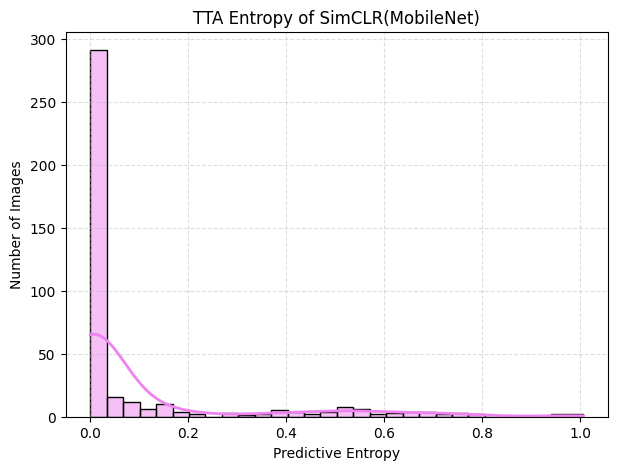

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Predictive entropy
entropy = -np.sum(probs * np.log(probs + 1e-8), axis=1)

# Plot uncertainty distribution
plt.figure(figsize=(7,5))

sns.histplot(entropy, bins=30, kde=True, color="violet",
             line_kws={"linewidth": 2, "color": "purple"})  # bolder KDE line

plt.title("TTA Entropy of SimCLR(MobileNet)")
plt.xlabel("Predictive Entropy")
plt.ylabel("Number of Images")

plt.grid(True, linestyle='--', alpha=0.4)

plt.show()

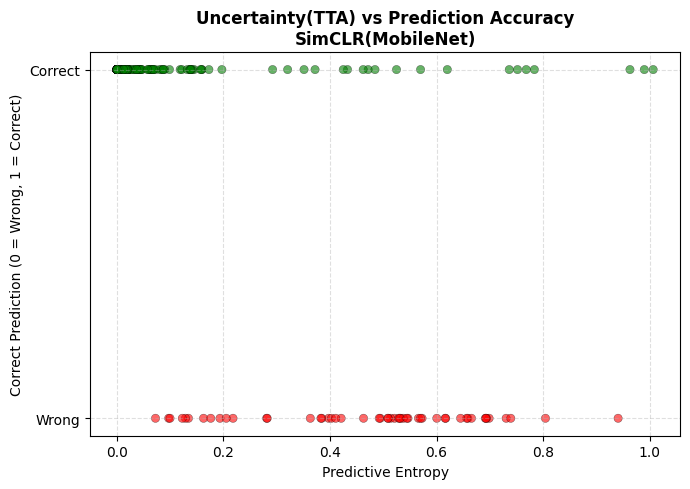

In [24]:
import numpy as np
import matplotlib.pyplot as plt

preds_tta = clf.predict(
    X_val
)


tta_acc = np.mean(
    preds_tta == test_labels
)
# ============================================================
# Correct / Wrong Prediction
# ============================================================

correct = (
    preds_tta == test_labels
)



# ============================================================
# Color Mapping
# ============================================================

colors = np.where(
    correct,
    "green",
    "red"
)



# ============================================================
# Uncertainty vs Accuracy Plot
# ============================================================

plt.figure(figsize=(7,5))


plt.scatter(
    entropy,
    correct,
    c=colors,
    alpha=0.6,
    edgecolor="black",
    linewidth=0.3
)



plt.title(
    "Uncertainty(TTA) vs Prediction Accuracy\nSimCLR(MobileNet)",
    fontsize=12,
    fontweight="semibold"
)



plt.xlabel(
    "Predictive Entropy"
)


plt.ylabel(
    "Correct Prediction (0 = Wrong, 1 = Correct)"
)



plt.yticks(
    [0,1],
    ["Wrong","Correct"]
)



plt.grid(
    axis="both",
    linestyle="--",
    alpha=0.4
)



plt.tight_layout()

plt.show()

# **Prediction Confidence Distribution**

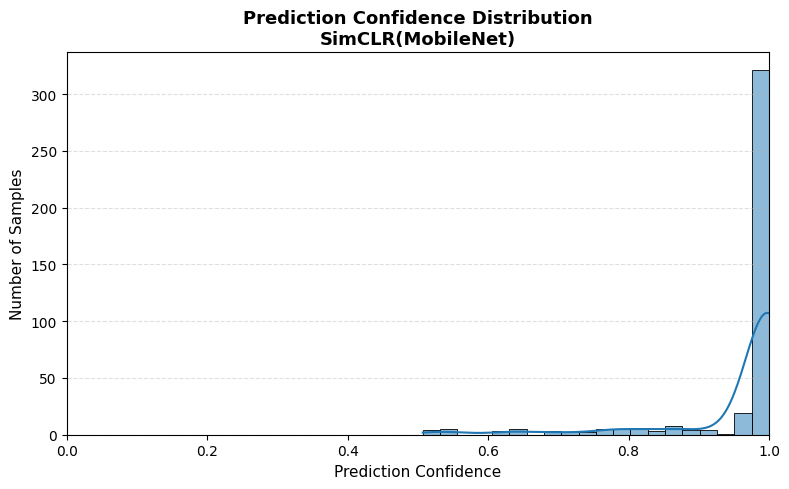

Average Confidence: 0.9601042


In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# Prediction Confidence
# ============================================================

confidence = np.max(
    probs,
    axis=1
)



# ============================================================
# Confidence Distribution Plot
# ============================================================

plt.figure(figsize=(8,5))


sns.histplot(
    confidence,
    bins=20,
    kde=True,
    edgecolor="black",
    linewidth=0.6
)



plt.title(
    "Prediction Confidence Distribution\nSimCLR(MobileNet)",
    fontsize=13,
    fontweight="bold"
)



plt.xlabel(
    "Prediction Confidence",
    fontsize=11
)


plt.ylabel(
    "Number of Samples",
    fontsize=11
)



plt.xlim(
    0,
    1
)



plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)



plt.tight_layout()

plt.show()



print(
    "Average Confidence:",
    np.mean(confidence)
)

# **Misclassified Samples Analysis**

In [26]:
mis_idx = np.where(preds != test_labels)[0]

print("Misclassified samples:", len(mis_idx))

for i in mis_idx[:10]:
    print("True:", test_labels[i], "Pred:", preds[i])

Misclassified samples: 51
True: Decidual_tissue Pred: Hemorrhage
True: Decidual_tissue Pred: Trophoblastic_tissue
True: Decidual_tissue Pred: Hemorrhage
True: Decidual_tissue Pred: Hemorrhage
True: Decidual_tissue Pred: Hemorrhage
True: Decidual_tissue Pred: Hemorrhage
True: Decidual_tissue Pred: Hemorrhage
True: Decidual_tissue Pred: Hemorrhage
True: Decidual_tissue Pred: Hemorrhage
True: Decidual_tissue Pred: Hemorrhage


# **Entropy Distribution by Class**

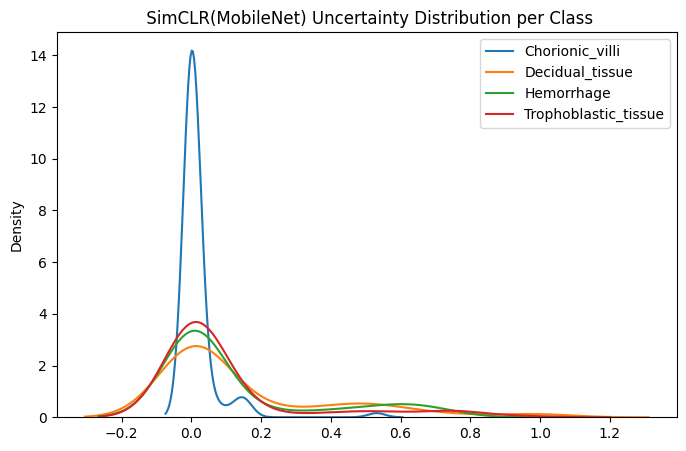

In [27]:
plt.figure(figsize=(8,5))

for cls in le.classes_:
    idx = np.array(test_labels) == cls
    sns.kdeplot(uncertainty[idx], label=cls)

plt.title(" SimCLR(MobileNet) Uncertainty Distribution per Class")
plt.legend()
plt.show()